# Minecraft-ifying a real volcano

Lake Balaton, Hungary's "inland sea", is ringed by the eroded stumps of extinct volcanoes. The most iconic one, **Badacsony**, is a basalt plug covered in vineyards that has been a postcard motif for over a century.

This library ships a real digital terrain model of it (`download_badacsony`), so let's put it to work: we'll voxelize the mountain with `voxelize_T3_H8` and turn it into a blocky, Minecraft-style landscape, along the way picking up everything you need to convert *any* scanned or triangulated surface into a hexahedral grid.

In [1]:
from sigmaepsilon.mesh.downloads import download_badacsony

mesh = download_badacsony(read=True)
leaf = mesh[5]
coords_T3 = mesh.coords()
topo_T3 = leaf.cd.topology().to_numpy()

print(f"{mesh.number_of_points()} points, {mesh.number_of_cells()} triangles")
print(f"footprint area: {leaf.area():,.0f} (data units squared)")
print(f"bounding box: {coords_T3.min(axis=0)} -> {coords_T3.max(axis=0)}")

482000 points, 963996 triangles
footprint area: 57,186 (data units squared)
bounding box: [-280.    0.    0.] -> [5.5109106e-15 9.0000000e+01 4.0000000e+01]


## The real thing

First, let's look at the actual triangulated surface, colored by elevation. A `PyVista` plotter gives us more control over the colormap than the `plot` convenience method, so we build one directly from `PolyData.to_pv`.

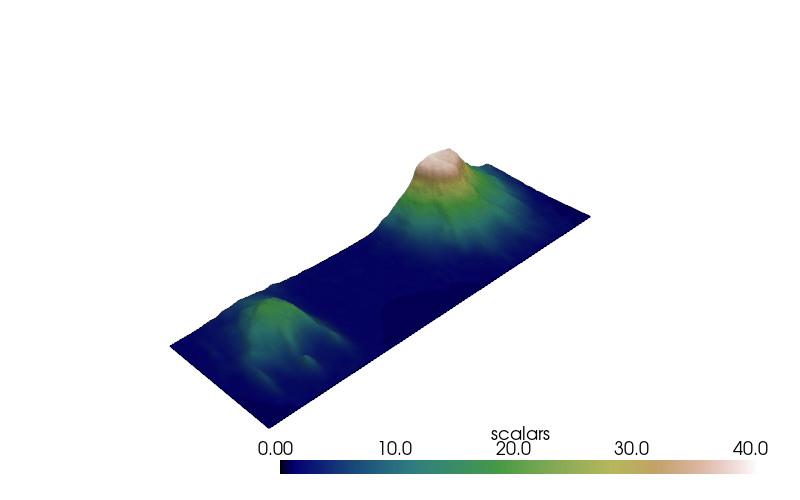

In [2]:
import pyvista as pv

pv_mesh = mesh.to_pv(multiblock=False, scalars=coords_T3[:, 2])[0]

plotter = pv.Plotter(notebook=True, window_size=(800, 500))
plotter.add_mesh(pv_mesh, cmap="gist_earth", show_edges=False)
plotter.camera_position = "iso"
plotter.show(jupyter_backend="static")

## From triangles to blocks

`voxelize_T3_H8` covers the bounding box of a triangulated surface with a regular grid of hexahedra ("voxels"), and keeps only the ones that are actually intersected by the surface. That's exactly the operation you need to turn a 3d scan or an STL file into a finite-element-ready hexahedral mesh -- here we'll just (ab)use it for cartography.

In [3]:
import numpy as np
from sigmaepsilon.mesh.voxelize import voxelize_T3_H8

shape = (90, 30, 20)  # number of voxels along x, y, z
coords_H8, topo_H8 = voxelize_T3_H8(coords_T3, topo_T3, shape=shape)

print(f"{topo_H8.shape[0]} voxels carved out of a {np.prod(shape)}-voxel bounding box")

5810 voxels carved out of a 54000-voxel bounding box


There's a catch: `voxelize_T3_H8` only keeps the voxels that touch the surface. The result is a thin *shell* -- structurally, our mountain is completely hollow, like a stage prop. We can see it by slicing through it.

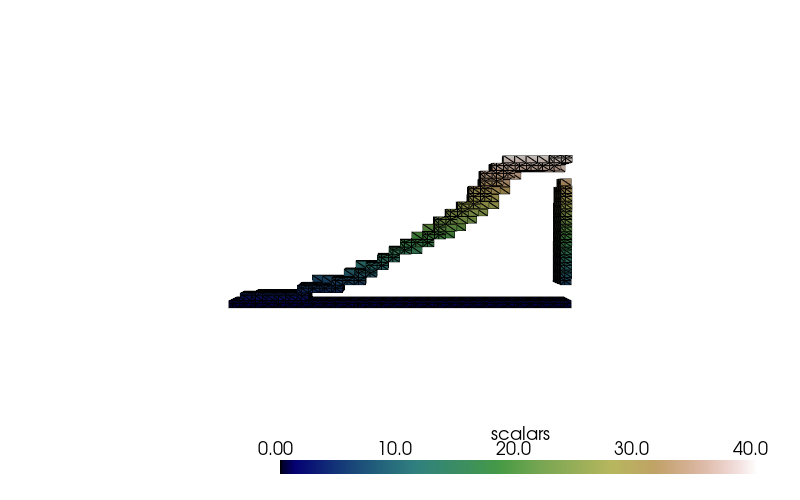

In [4]:
from sigmaepsilon.mesh import PolyData, PointData, CartesianFrame
from sigmaepsilon.mesh.cells import H8

frame = CartesianFrame(dim=3)
point_scalars = coords_H8[:, 2]


def voxels_to_pv(topo):
    pd = PointData(coords=coords_H8, frame=frame)
    cd = H8(topo=topo, frames=frame)
    return PolyData(pd, cd).to_pv(multiblock=False, scalars=point_scalars)[0]


shell_pv = voxels_to_pv(topo_H8)

peak = coords_T3[np.argmax(coords_T3[:, 2])]
resolution = (coords_T3.max(axis=0) - coords_T3.min(axis=0)) / shape
bounds = list(shell_pv.bounds)
bounds[0], bounds[1] = peak[0] - 2 * resolution[0], peak[0] + 2 * resolution[0]
shell_slice = shell_pv.clip_box(bounds, invert=False)

plotter = pv.Plotter(notebook=True, window_size=(800, 500))
plotter.add_mesh(shell_slice, cmap="gist_earth", show_edges=True)
plotter.camera_position = [
    (peak[0] - 250, peak[1] + 45, peak[2] - 15),
    (peak[0], peak[1] + 45, peak[2] - 25),
    (0, 0, 1),
]
plotter.show(jupyter_backend="static")

## Solidifying the mountain

To get a proper Minecraft mountain, every voxel column needs to be filled in, from the ground up to wherever the shell says the surface is. We find the highest occupied voxel in every `(x, y)` column, then keep every voxel below it, using the full dense grid `voxelize_T3_H8` builds internally.

In [5]:
from sigmaepsilon.mesh.grid import grid
from sigmaepsilon.mesh.utils.topology.cic import H8_in_T3

size = coords_T3.max(axis=0) - coords_T3.min(axis=0)
shift = coords_T3.min(axis=0)
coords_H8, topo_H8_dense = grid(size=tuple(size), shape=shape, eshape="H8", shift=tuple(shift))
shell_mask = H8_in_T3(coords_H8, topo_H8_dense, coords_T3, topo_T3, k=10)

centers = coords_H8[topo_H8_dense].mean(axis=1)
ix, iy, iz = np.clip(
    np.floor((centers - shift) / resolution).astype(int), 0, np.array(shape) - 1
).T

column_top = {}
for x, y, z, hit in zip(ix, iy, iz, shell_mask):
    if hit:
        column_top[(x, y)] = max(z, column_top.get((x, y), -1))

solid_mask = np.array(
    [z <= column_top.get((x, y), -1) for x, y, z in zip(ix, iy, iz)]
)

voxel_mountain = PolyData(
    PointData(coords=coords_H8, frame=frame),
    H8(topo=topo_H8_dense[solid_mask], frames=frame),
)

print(f"{solid_mask.sum()} solid blocks, {voxel_mountain.volume():,.0f} cubic units")

10082 solid blocks, 188,197 cubic units


Slicing the solid version at the same spot now shows a mountain with actual substance, the way a Minecraft player would expect it -- compare this to the hollow shell above.

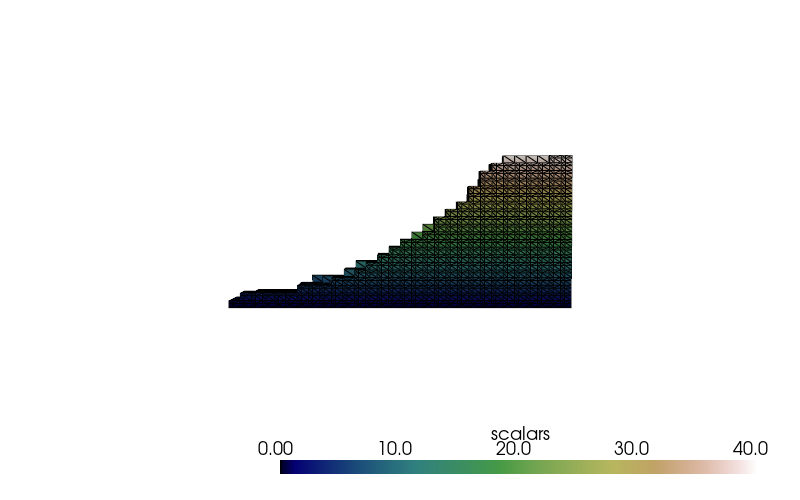

In [6]:
solid_pv = voxels_to_pv(topo_H8_dense[solid_mask])
solid_slice = solid_pv.clip_box(bounds, invert=False)

plotter = pv.Plotter(notebook=True, window_size=(800, 500))
plotter.add_mesh(solid_slice, cmap="gist_earth", show_edges=True)
plotter.camera_position = [
    (peak[0] - 250, peak[1] + 45, peak[2] - 15),
    (peak[0], peak[1] + 45, peak[2] - 25),
    (0, 0, 1),
]
plotter.show(jupyter_backend="static")

## The hero shot

With the mountain solidified, here's the full blocky Badacsony, viewed the way it earned its postcard fame -- just chunkier.

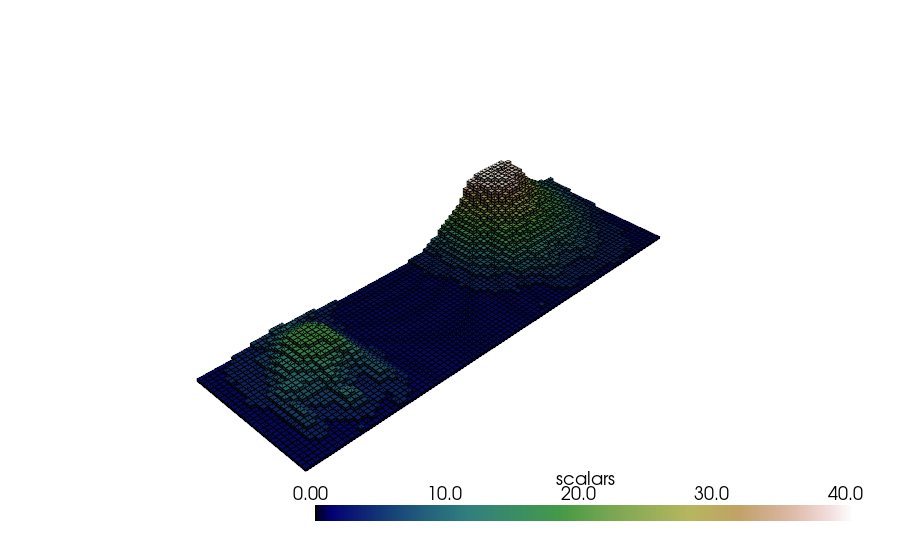

In [7]:
plotter = pv.Plotter(notebook=True, window_size=(900, 550))
plotter.add_mesh(solid_pv, cmap="gist_earth", show_edges=True, lighting=True)
plotter.camera_position = "iso"
plotter.show(jupyter_backend="static")

## Does resolution matter?

As we refine the voxel grid, the blocky volume should converge to the true volume under the terrain. Let's check that with a much coarser grid, repeating the same column-fill trick.

In [8]:
def solidify(shape):
    coords_H8, topo_H8_dense = grid(size=tuple(size), shape=shape, eshape="H8", shift=tuple(shift))
    shell_mask = H8_in_T3(coords_H8, topo_H8_dense, coords_T3, topo_T3, k=10)
    res = size / np.array(shape)
    centers = coords_H8[topo_H8_dense].mean(axis=1)
    ix, iy, iz = np.clip(np.floor((centers - shift) / res).astype(int), 0, np.array(shape) - 1).T
    column_top = {}
    for x, y, z, hit in zip(ix, iy, iz, shell_mask):
        if hit:
            column_top[(x, y)] = max(z, column_top.get((x, y), -1))
    solid_mask = np.array([z <= column_top.get((x, y), -1) for x, y, z in zip(ix, iy, iz)])
    pdata = PolyData(
        PointData(coords=coords_H8, frame=frame),
        H8(topo=topo_H8_dense[solid_mask], frames=frame),
    )
    return pdata, coords_H8

coarse_shape = (30, 10, 7)
coarse_mountain, coarse_coords = solidify(coarse_shape)

print(f"coarse grid {coarse_shape}: {coarse_mountain.number_of_cells()} blocks, "
      f"{coarse_mountain.volume():,.0f} cubic units")
print(f"fine grid   {shape}: {voxel_mountain.number_of_cells()} blocks, "
      f"{voxel_mountain.volume():,.0f} cubic units")

coarse grid (30, 10, 7): 555 blocks, 266,400 cubic units
fine grid   (90, 30, 20): 10082 blocks, 188,197 cubic units


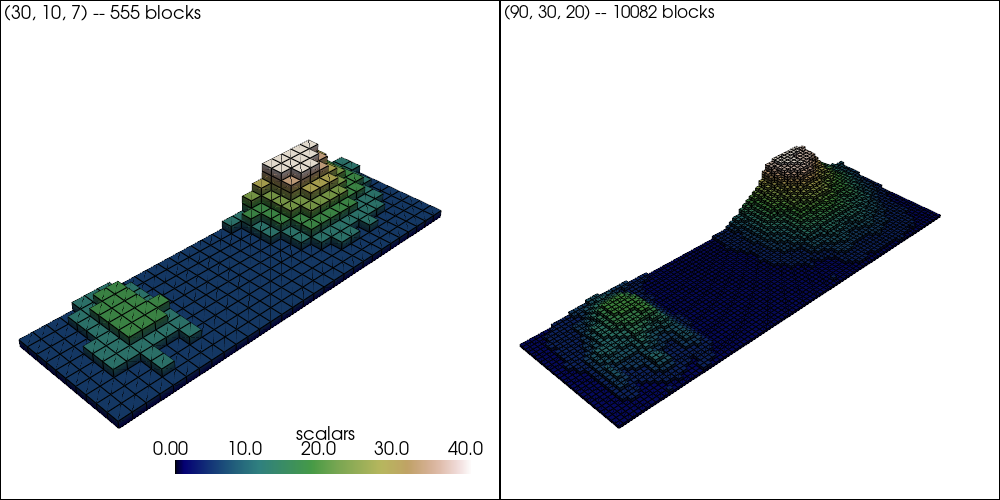

In [9]:
coarse_pv = coarse_mountain.to_pv(multiblock=False, scalars=coarse_coords[:, 2])[0]

plotter = pv.Plotter(notebook=True, window_size=(1000, 500), shape=(1, 2))
plotter.subplot(0, 0)
plotter.add_mesh(coarse_pv, cmap="gist_earth", show_edges=True)
plotter.add_text(f"{coarse_shape} -- {coarse_mountain.number_of_cells()} blocks", font_size=10)
plotter.camera_position = "iso"
plotter.subplot(0, 1)
plotter.add_mesh(solid_pv, cmap="gist_earth", show_edges=True)
plotter.add_text(f"{shape} -- {voxel_mountain.number_of_cells()} blocks", font_size=10)
plotter.camera_position = "iso"
plotter.show(jupyter_backend="static")

## Beyond the gimmick

Turning a postcard volcano into building blocks is just the fun wrapper. The actual machinery -- `voxelize_T3_H8` plus this column-fill trick -- is exactly how you'd convert a 3d scan or an arbitrary STL surface (see `download_bunny`, `download_stand` or `download_bike_stem`) into a watertight hexahedral mesh, ready for a finite element or finite volume solver. Same recipe, fewer vineyards.